load info

In [15]:
# copy from Starloc.ipynb step 1, for basic info loading
from utils.calibration import CalibrationSignal
from utils.imu_data import IMUData
import os
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
iq0_path = '/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_04_19_33_freq_11_325G_bw_2.0M_ts_1709698773.3134246_inrx0.dat'
imu = IMUData('/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_04_19_12.txt')
iq1_path = iq0_path.replace('inrx0', 'inrx1')
iq2_path = iq0_path.replace('inrx0', 'inrx2')
date = iq0_path.split('_')[-12]+'_'+iq0_path.split('_')[-11]+'_'+iq0_path.split('_')[-10]
start_time = float(iq0_path.split('_')[-2])
# date = '5Feb2024_23-58-08'
# start_time = 1707177488.0938272
fc = 11.325e9
sample_rate = 2e6

real world data

In [18]:
# for AoA simulation
from sat_id import aoa_sim_1_sat, aoa_sim_1_sat_eph
dopp_track_dict = sio.loadmat(date+'/phase_comp.mat')['dopp_track_dict']
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']
sat_dopp_struct = sio.loadmat(date+'/phase_comp.mat')['sat_dopp_dict']
ref_sig_idx = sio.loadmat(date+'/info.mat')['ref_sig_idx']
phase_offset_01 = sio.loadmat(date+'/info.mat')['phase_offset_01'][0]
phase_offset_21 = sio.loadmat(date+'/info.mat')['phase_offset_21'][0]
lat_gt = sio.loadmat(date+'/info.mat')['lat_gt'][0][0]
lon_gt = sio.loadmat(date+'/info.mat')['lon_gt'][0][0]
# lat_gt, lon_gt = 40.07217018221909, -88.2094858793905
coarse_lat = sio.loadmat(date+'/blind_id.mat')['coarse_lat'][0][0]
coarse_lon = sio.loadmat(date+'/blind_id.mat')['coarse_lon'][0][0]
sat_num = len(dopp_track_dict[0, :])

az_gt_list, el_gt_list, range_gt_list, t_sim_list = [], [], [], []

for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    t_sat_start, t_sat_end = t_repeat[0].real, t_repeat[-1].real
    t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .001, coarse_lat, coarse_lon)
    t_sim += t_sat_start
    az_gt = np.radians(az_gt)
    el_gt = np.radians(el_gt)

    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    t_sim_list.append(t_sim)

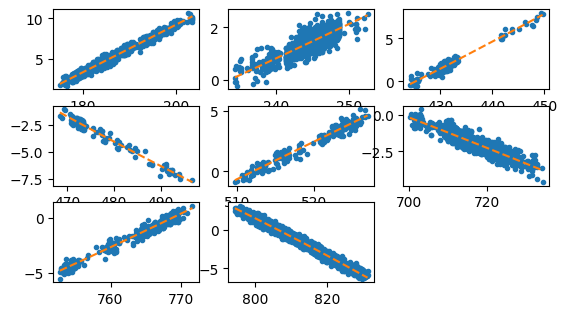

In [19]:
# for phase diff compensation (including phase offset from USRP & LNB)
del_phi_01_list, del_phi_12_list = [], []
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    t_sat_start, t_sat_end = t_repeat[0].real, t_repeat[-1].real

    # subtract the ref sig's phase
    ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-t_sat_start))
    phase_offset_01_ = phase_offset_01[ref_sig_ii]
    phase_offset_12_ = -phase_offset_21[ref_sig_ii]

    del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3])) - phase_offset_01_
    del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4])) - phase_offset_12_

    # polyfit
    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))

    plt.subplot(4, 3, sat_idx+1)
    plt.plot(t_repeat, del_phi_repeat_01, '.')
    plt.plot(t_repeat, np.polyval(coeff_01, t_repeat), '--')
    del_phi_01_list.append(np.polyval(coeff_01, t_sim_list[sat_idx]))
    del_phi_12_list.append(np.polyval(coeff_12, t_sim_list[sat_idx]))
    
plt.show()

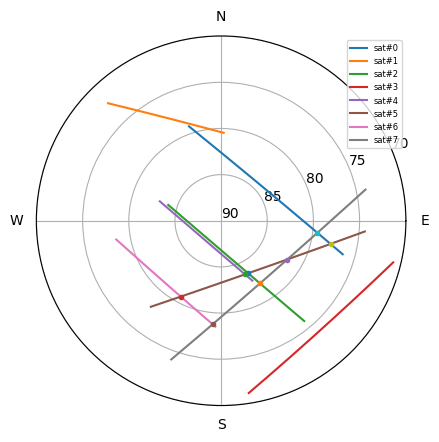

In [20]:
# find the intersection, calc phase_err_mat
def my_mod(x, y):
    tmp = np.mod(x, y)
    if tmp > y/2:
        tmp -= y
    return tmp

# %matplotlib widget
for sat_idx in range(sat_num):
    plt.polar(np.deg2rad(90)-az_gt_list[sat_idx], 90-np.rad2deg(el_gt_list[sat_idx]), label='sat#'+str(sat_idx))
    # plt.polar(np.deg2rad(90)-az_1[i_min], 90-np.rad2deg(el_1[i_min]), 'o', label='intersec')

phase_err_mat = np.full((sat_num, sat_num, 2), np.nan)
for sat_1 in range(sat_num):
    phase_err_mat[sat_1, sat_1, :] = 0
for sat_1 in range(sat_num):
    theta = np.deg2rad(90)-az_gt_list[sat_1]
    r = 90-np.rad2deg(el_gt_list[sat_1])
    x_1, y_1 = r*np.cos(theta), r*np.sin(theta)
    k_1, b_1 = np.polyfit(x_1, y_1, 1)
    for sat_2 in range(sat_1+1, sat_num):
        theta = np.deg2rad(90)-az_gt_list[sat_2]
        r = 90-np.rad2deg(el_gt_list[sat_2])
        x_2, y_2 = r*np.cos(theta), r*np.sin(theta)
        k_2, b_2 = np.polyfit(x_2, y_2, 1)
        # intersect of two lines
        x_intersect = (b_2-b_1)/(k_1-k_2)
        y_intersect = k_1*x_intersect+b_1
        if (x_intersect-x_1[0])*(x_intersect-x_1[-1]) < 0 and (x_intersect-x_2[0])*(x_intersect-x_2[-1]) < 0:
            # find the index of the intersect
            i_min = np.argmin(np.abs(x_1-x_intersect))
            j_min = np.argmin(np.abs(x_2-x_intersect))
            plt.polar(np.deg2rad(90)-az_gt_list[sat_1][i_min], 90-np.rad2deg(el_gt_list[sat_1][i_min]), '.')
            phase_err_mat[sat_1, sat_2, 0] = my_mod(del_phi_01_list[sat_1][i_min]-del_phi_01_list[sat_2][j_min], 2*np.pi)
            phase_err_mat[sat_1, sat_2, 1] = my_mod(del_phi_12_list[sat_1][i_min]-del_phi_12_list[sat_2][j_min], 2*np.pi)

plt.xticks(np.deg2rad([0,90,180,270]), ['E', 'N', 'W', 'S'])
plt.yticks([0, 5, 10, 15, 20], ['90', '85', '80', '75', '70'])
plt.legend(fontsize=6)
plt.show()

In [21]:
print(np.round(phase_err_mat[:,:,0],4))
print('\n')
print(np.round(phase_err_mat[:,:,1],4))

[[ 0.         nan     nan     nan     nan  0.2288     nan  0.0868]
 [    nan  0.         nan     nan     nan     nan     nan     nan]
 [    nan     nan  0.         nan     nan -0.2107     nan -0.1682]
 [    nan     nan     nan  0.         nan     nan     nan     nan]
 [    nan     nan     nan     nan  0.     -0.359      nan     nan]
 [    nan     nan     nan     nan     nan  0.      0.4176 -0.0638]
 [    nan     nan     nan     nan     nan     nan  0.     -0.2463]
 [    nan     nan     nan     nan     nan     nan     nan  0.    ]]


[[0.        nan    nan    nan    nan 0.2903    nan 0.3474]
 [   nan 0.        nan    nan    nan    nan    nan    nan]
 [   nan    nan 0.        nan    nan 0.0231    nan 0.0756]
 [   nan    nan    nan 0.        nan    nan    nan    nan]
 [   nan    nan    nan    nan 0.     0.2805    nan    nan]
 [   nan    nan    nan    nan    nan 0.     0.0312 0.0673]
 [   nan    nan    nan    nan    nan    nan 0.     0.0034]
 [   nan    nan    nan    nan    nan    nan    n

In [51]:
# compare with simulation phase diff, calculate the gap
del_phi_01_gt_list, del_phi_12_gt_list = [], []
d, lam = 13.25e-2, 3e8/fc
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])
orient = imu.get_attitude()
yaw, pitch, roll = np.mean(orient[2][-3000:-1]), np.mean(orient[1]), np.mean(orient[0])
R_yaw = np.array([[np.cos(np.deg2rad(yaw)), -np.sin(np.deg2rad(yaw)), 0], [np.sin(np.deg2rad(yaw)), np.cos(np.deg2rad(yaw)), 0], [0, 0, 1]])
R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])
R = R_yaw @ R_pitch @ R_roll
loc_0, loc_2 = R @ loc_0, R @ loc_2

gap_01_arr, gap_12_arr = np.array([]), np.array([])
# 2
# ph_01 = np.array([0.102, 0.123, 0.145, 0.166, -0.123, 0, 0.259, 0.318])
# ph_12 = np.array([-0.28, -0.445, -0.53, -0.504, 0.01, 0, -0.219, -0.293])
# 3
# ph_01 = np.array([-0.29, 0, 0.151, 0, 0.291, 0, 0.37, -0.114])
# ph_12 = np.array([-0.305, 0, -0.035, 0, -0.295, 0, 0.018, 0.054])
# 7
# ph_01 = np.array([0, 0.33, 0.399, 0.399, 0])
# ph_12 = np.array([0, -0.445, -0.229, -0.21, 0])
# 9
ph_01 = np.array([0, -0.073, -0.148, 0.119, -0.1, -0.192, -0.709])
ph_12 = np.array([0, -0.015, 0.059, 0.05, 0.095, 0.541, 0.822])


for sat_idx in range(sat_num):
    del_phi_01_list[sat_idx] += ph_01[sat_idx]
    del_phi_12_list[sat_idx] += ph_12[sat_idx]


for sat_idx in range(sat_num):
    az_gt = az_gt_list[sat_idx]
    el_gt = el_gt_list[sat_idx]
    range_gt = range_gt_list[sat_idx]
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt)))

    range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
    range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
    range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
    del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

    # calculate gap
    gap_01 = np.mean(del_phi_01_gt-del_phi_01_list[sat_idx])
    gap_12 = np.mean(del_phi_12_gt-del_phi_12_list[sat_idx])
    
    while np.abs(gap_01-np.mean(gap_01_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_01-np.mean(gap_01_arr))
        gap_01 -= tmp
        del_phi_01_list[sat_idx] += tmp
    while np.abs(gap_12-np.mean(gap_12_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_12-np.mean(gap_12_arr))
        gap_12 -= tmp
        del_phi_12_list[sat_idx] += tmp

    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    gap_01_arr = np.append(gap_01_arr, gap_01)
    gap_12_arr = np.append(gap_12_arr, gap_12)

/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


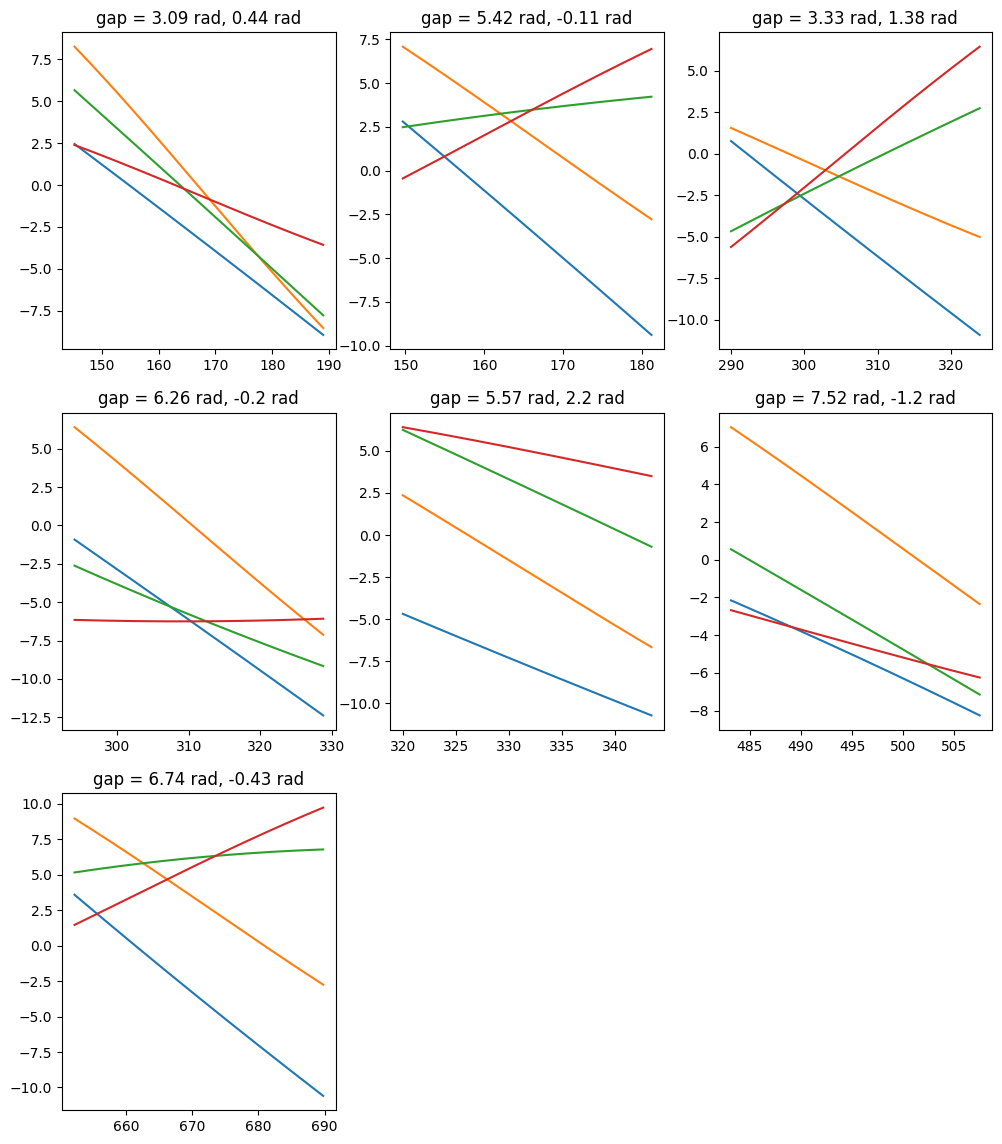

In [52]:
# big figure
plt.figure(figsize=(12, 14))
gap_arr = np.array([])
for sat_idx in range(sat_num):
    plt.subplot(3, 3, sat_idx+1)
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    # plot phi-01
    plt.plot(t_sim_list[sat_idx], del_phi_01_list[sat_idx])
    plt.plot(t_sim_list[sat_idx], del_phi_01_gt_list[sat_idx])
    gap_01 = np.mean(-del_phi_01_list[sat_idx] + del_phi_01_gt_list[sat_idx])
    # plot phi-12
    plt.plot(t_sim_list[sat_idx], del_phi_12_list[sat_idx])
    plt.plot(t_sim_list[sat_idx], del_phi_12_gt_list[sat_idx])
    gap_12 = np.mean(-del_phi_12_list[sat_idx] + del_phi_12_gt_list[sat_idx])
    plt.title('gap = '+str(round(gap_01, 2))+' rad, '+str(round(gap_12, 2))+' rad')
plt.show()

In [45]:
# localization
from tqdm import tqdm
x_grid, y_grid = np.linspace(-3e3, 3e3, 50), np.linspace(-3e3, 3e3, 50)
err_min = np.inf
num_sat_for_training = 1
for x in tqdm(x_grid):
    for y in y_grid:
        err = 0
        # add some offset to the ground truth location
        loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
        # only look at testing satellites
        for sat_idx in range(num_sat_for_training, sat_num):
            mes_01 = del_phi_01_list[sat_idx] + np.mean(gap_01_arr[0:num_sat_for_training])
            mes_12 = del_phi_12_list[sat_idx] + np.mean(gap_12_arr[0:num_sat_for_training])
            
            az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
            loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
            range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
            range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
            del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
            del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

            err += np.sum(np.abs(mes_12-del_phi_12_gt)) + np.sum(np.abs(mes_01-del_phi_01_gt))

        # print(err)
        if err < err_min:
            err_min = err
            loc_min = np.array([x,y])

print('error = ', np.linalg.norm(loc_min), 'm')
print('2d location away from gt:', loc_min, 'm')


100%|██████████| 50/50 [00:06<00:00,  7.54it/s]

error =  3991.34841134856 m
2d location away from gt: [ 3000.         -2632.65306122] m


In [16]:
print('2d location away from gt:', loc_min, 'm')

2d location away from gt: [775.51020408 448.97959184] m


In [35]:
# do grid search
from tqdm import tqdm
# ang_10_1_grid, ang_10_2_grid = np.array([np.rad2deg(ang_10_1)]), np.linspace(-ang_bound, ang_bound, 500)
ang_bound = 3 # degree
ang_10_1_grid, ang_10_2_grid = np.linspace(-ang_bound, ang_bound, 1000), np.linspace(-ang_bound, ang_bound, 1000)
ang_12_1_grid, ang_12_2_grid = np.linspace(-ang_bound, ang_bound, 1000), np.linspace(-ang_bound, ang_bound, 1000)

loc_1 = np.array([0,0,0])   # suppose rx1 is at the origin
num_sat_for_training = 3

print('start grid search for ang_10_1, ang_10_2')
err_min_10 = np.inf
for ang_10_1_search in tqdm(ang_10_1_grid):
    ang_10_1_search = np.deg2rad(ang_10_1_search)
    for ang_10_2_search in ang_10_2_grid:
        err_arr = np.array([])
        ang_10_2_search = np.deg2rad(ang_10_2_search)
        loc_0 = d * np.array([-np.cos(ang_10_2_search)*np.sin(ang_10_1_search), -np.cos(ang_10_2_search)*np.cos(ang_10_1_search), -np.sin(ang_10_2_search)])

        for sat_idx in range(num_sat_for_training):
            az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
            loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
            range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
            del_phi_01 = -(range_0-range_1)/lam*2*np.pi

            # different kinds of loss funcs            
            err_arr = np.append(err_arr, np.abs(del_phi_01-del_phi_01_gt_list[sat_idx]))
            # err_arr = np.append(err_arr, np.abs(np.diff(del_phi_01)-np.diff(del_phi_01_gt_list[sat_idx])))
        # err = np.sum(err_arr)
        err = np.var(err_arr)
        if err < err_min_10:
            err_min_10 = err
            ang_min_10 = np.array([ang_10_1_search, ang_10_2_search])

print('start grid search for ang_12_1, ang_12_2')
err_min_12 = np.inf
for ang_12_1_search in tqdm(ang_12_1_grid):
    ang_12_1_search = np.deg2rad(ang_12_1_search)
    for ang_12_2_search in ang_12_2_grid:
        err_arr = np.array([])
        ang_12_2_search = np.deg2rad(ang_12_2_search)
        loc_2 = d * np.array([np.cos(ang_12_2_search)*np.cos(ang_12_1_search), -np.cos(ang_12_2_search)*np.sin(ang_12_1_search), np.sin(ang_12_2_search)])
        for sat_idx in range(num_sat_for_training):
                        
            az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
            loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
            range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
            del_phi_12 = -(range_1-range_2)/lam*2*np.pi
            
            err_arr = np.append(err_arr, np.abs(del_phi_12-del_phi_12_gt_list[sat_idx]))
            # err_arr = np.append(err_arr, np.abs(np.diff(del_phi_12)-np.diff(del_phi_12_gt_list[sat_idx])))
        # err = np.sum(err_arr)
        err = np.var(err_arr)
        if err < err_min_12:
            err_min_12 = err
            ang_min_12 = np.array([ang_12_1_search, ang_12_2_search])


start grid search for ang_10_1, ang_10_2


100%|██████████| 1000/1000 [01:28<00:00, 11.30it/s]


start grid search for ang_12_1, ang_12_2


100%|██████████| 1000/1000 [01:28<00:00, 11.31it/s]


In [36]:
print(np.rad2deg(ang_min_10))
print(np.rad2deg(ang_min_12))
# print(np.rad2deg(ang_10_1))
# print(np.rad2deg(ang_10_2))
# print(err_min_12)

[-0.32732733  3.        ]
[ 1.48648649 -1.57057057]


In [ ]:
loc_1 = np.array([0,0,0])   # suppose rx1 is at the origin
ang_10_1_opt, ang_10_2_opt = ang_min_10
ang_12_1_opt, ang_12_2_opt = ang_min_12
loc_0 = d * np.array([-np.cos(ang_10_2_opt)*np.sin(ang_10_1_opt), -np.cos(ang_10_2_opt)*np.cos(ang_10_1_opt), -np.sin(ang_10_2_opt)])
loc_2 = d * np.array([np.cos(ang_12_2_opt)*np.cos(ang_12_1_opt), -np.cos(ang_12_2_opt)*np.sin(ang_12_1_opt), np.sin(ang_12_2_opt)])
del_phi_01_list, del_phi_12_list = [], []
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0]
    t_sat_start, t_sat_end = t_repeat[0].real, t_repeat[-1].real

    t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1)
    t_sim += t_sat_start
    az_gt = np.radians(az_gt)
    el_gt = np.radians(el_gt)
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

    range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
    range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
    range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
    del_phi_01 = -(range_0-range_1)/lam*2*np.pi
    del_phi_12 = -(range_1-range_2)/lam*2*np.pi
    del_phi_01_list.append(del_phi_01)
    del_phi_12_list.append(del_phi_12)

# plot a large fig
# plot for phase diff
plt.figure(figsize=(10, 10))
# plt.title('d_10='+str(round(d_10,3))+', d_12='+str(round(d_12,3)))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt')
    plt.plot(t_sim, del_phi_01_list[sat_idx], '--')

    plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt')
    plt.plot(t_sim, del_phi_12_list[sat_idx], '--')
    plt.title('gap01='+str(round(np.mean(del_phi_01_list[sat_idx]-del_phi_01_gt_list[sat_idx]),3))+', gap12='+str(round(np.mean(del_phi_12_list[sat_idx]-del_phi_12_gt_list[sat_idx]),3)))
plt.show()
# plot for derivative of phase diff
plt.figure(figsize=(10, 10))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(t_sim[0:-1], np.diff(del_phi_01_gt_list[sat_idx]), label='gt')
    plt.plot(t_sim[0:-1], np.diff(del_phi_01_list[sat_idx]), '--')

    plt.plot(t_sim[0:-1], np.diff(del_phi_12_gt_list[sat_idx]), label='gt')
    plt.plot(t_sim[0:-1], np.diff(del_phi_12_list[sat_idx]), '--')
plt.show()

In [26]:
for id_2 in range(8):
    # id_1, id_2 = 5, 2
    id_1 = 5
    az_1, el_1 = az_gt_list[id_1], el_gt_list[id_1]
    az_2, el_2 = az_gt_list[id_2], el_gt_list[id_2]
    t_1, t_2 = t_sim_arr[id_1], t_sim_arr[id_2]
    min_dis = np.inf
    for i in range(len(az_1)):
        for j in range(len(az_2)):
            dis = np.linalg.norm(np.array([az_1[i], el_1[i]])-np.array([az_2[j], el_2[j]]))
            if dis < min_dis:
                min_dis = dis
                i_min, j_min = i, j
                if min_dis < 1e-2:
                    break
    t_1_min, t_2_min = t_1[i_min], t_2[j_min]
    # for sat_idx in [id_1, id_2]:
    #     plt.polar(np.deg2rad(90)-az_gt_list[sat_idx], 90-np.rad2deg(el_gt_list[sat_idx]), '.', label='sat#'+str(sat_idx+1))
    # plt.polar(np.deg2rad(90)-az_1[i_min], 90-np.rad2deg(el_1[i_min]), 'o', label='intersec')
    # # set the x ticks to be north, west, south, east
    # plt.xticks(np.deg2rad([0,90,180,270]), ['E', 'N', 'W', 'S'])
    # plt.yticks([0, 5, 10, 15, 20], ['90', '85', '80', '75', '70'])
    # plt.legend()
    # plt.show()

    # print(del_phi_01_gt_list[id_1][i_min])
    # print(del_phi_01_gt_list[id_2][j_min])
    print(del_phi_01_gt_list[id_1][i_min] - del_phi_01_gt_list[id_2][j_min])
    # print(del_phi_12_gt_list[id_1][i_min])
    # print(del_phi_12_gt_list[id_2][j_min])
    print(del_phi_12_gt_list[id_1][i_min] - del_phi_12_gt_list[id_2][j_min])

0.11410881092474234
-0.2777076245784684
0.1070385488338168
-0.4485516245111896
0.1543561913834921
-0.5275005178379573
0.15541238854620687
-0.5060701210567373
-0.14857574533419893
0.005405738105594082
0.0
0.0
0.26197299754081627
-0.21933156178249558
0.29897558725542694
-0.2697884101030894


In [7]:
-0.48449905632332957+0.5098683305806446

0.025369274257315055

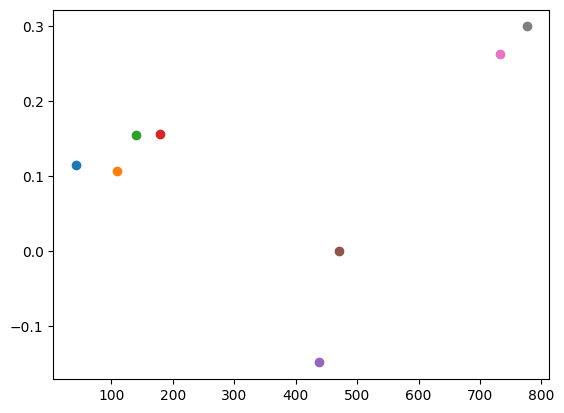

In [28]:
ph_01 = np.array([0.11410881092474234, 0.1070385488338168, 0.1543561913834921, 0.15541238854620687, -0.14857574533419893, 0, 0.26197299754081627, 0.29897558725542694])
ph_12 = np.array([-0.2777076245784684, -0.44921450272461527, -0.5275005178379573, -0.5060701210567373, 0.005405738105594082, 0, -0.21933156178249558, -0.2697884101030894])
for sat_idx in range(8):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    t_sat_start, t_sat_end = t_repeat[0], t_repeat[-1]
    plt.plot(t_sat_start/2+t_sat_end/2, ph_01[sat_idx], 'o')
plt.show()